Averages the lst data from 30 years into 3 raster datasets. 

In [6]:
import arcpy 
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [7]:
DATA_DIRECTORY = r"./data/lst_c_tiff"
OUTPUT_DIR = r"./data/avg_lst_10y_tiff/"

# Loading Data

In [8]:
data_dir = Path(DATA_DIRECTORY).resolve()
print(f"[INFO] Scanning directory: {data_dir}")

tif_files = sorted(
        [f for f in data_dir.iterdir() if f.suffix.lower() in [".tif", ".tiff"]]
    )

print(f"[INFO] Found {len(tif_files)} files")

[INFO] Scanning directory: D:\Gus\geog606\code\data\lst_c_tiff
[INFO] Found 30 files


In [9]:
np_arrs = []

ref_raster = arcpy.Raster(str(tif_files[0]))

LOWER_LEFT = arcpy.Point(ref_raster.extent.XMin, ref_raster.extent.YMin)
CELL_SIZE = ref_raster.meanCellWidth
SPATIAL_REF = ref_raster.spatialReference

print(f"[INFO] Raster reference data\nTop left [{LOWER_LEFT}], cell size: {CELL_SIZE}, spatial reference {SPATIAL_REF}")

for file_path in tif_files:
    raster_obj = arcpy.Raster(str(file_path))

    # Read raster into numpy array
    arr = arcpy.RasterToNumPyArray(raster_obj, nodata_to_value=np.nan)
    np_arrs.append(arr)



[INFO] Raster reference data
Top left [483660 5449440 NaN NaN], cell size: 30.0, spatial reference <geoprocessing spatial reference object object at 0x00000232A4AEE830>


# Process

In [10]:
avg_10y_lst = [
    np.nanmean(np_arrs[:10], axis=0),
    np.nanmean(np_arrs[10:20], axis=0),
    np.nanmean(np_arrs[20:30], axis=0)
]

C:\Users\Gus\AppData\Local\Temp\ipykernel_63260\2915622522.py:2: RuntimeWarning: Mean of empty slice
  np.nanmean(np_arrs[:10], axis=0),
C:\Users\Gus\AppData\Local\Temp\ipykernel_63260\2915622522.py:3: RuntimeWarning: Mean of empty slice
  np.nanmean(np_arrs[10:20], axis=0),
C:\Users\Gus\AppData\Local\Temp\ipykernel_63260\2915622522.py:4: RuntimeWarning: Mean of empty slice
  np.nanmean(np_arrs[20:30], axis=0)


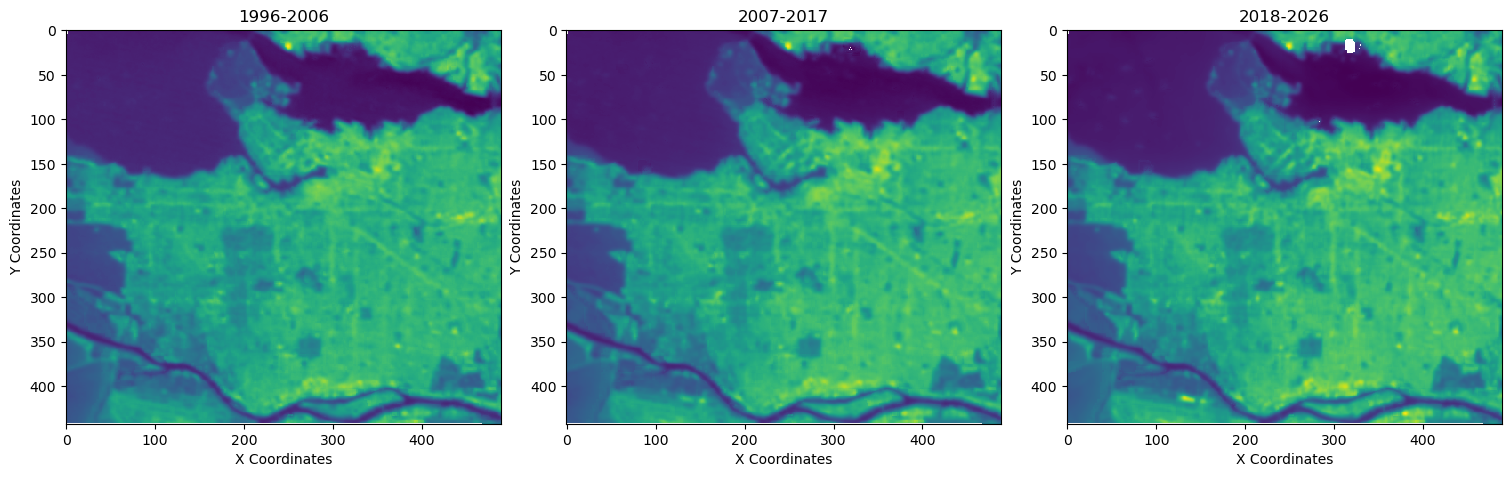

In [11]:
titles = ["1996-2006", "2007-2017", "2018-2026"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)

# 3. Loop through the arrays and axes to plot
# Using the same vmin and vmax keeps the data values visually comparable across panels

images = []

for i, ax in enumerate(axes):
    im = ax.imshow(avg_10y_lst[i], cmap="viridis", interpolation='none')
    images.append(im)
    
    ax.set_title(titles[i], fontsize=12)
    ax.set_xlabel("X Coordinates")
    ax.set_ylabel("Y Coordinates")
    ax.grid(False)  # Ensure gridlines don't overlay the raster pixels



# 5. Display or save the plot
plt.show()

# Save Results


In [13]:
arcpy.env.outputCoordinateSystem = SPATIAL_REF

out_names = [
    "lst_96",
    "lst_06",
    "lst_17"
]

for i, arr_loaded in enumerate(avg_10y_lst):
    out_raster = arcpy.NumPyArrayToRaster(
        arr_loaded,
        lower_left_corner=LOWER_LEFT,
        x_cell_size=CELL_SIZE,
        y_cell_size=CELL_SIZE,
        value_to_nodata=-999,
    )

    output_path = Path(OUTPUT_DIR + "/" + out_names[i] +".tif").resolve()
    print(f"[INFO] Output Path: {output_path}")

    out_raster.save(str(output_path))

[INFO] Output Path: D:\Gus\geog606\code\data\avg_lst_10y_tiff\lst_96.tif
[INFO] Output Path: D:\Gus\geog606\code\data\avg_lst_10y_tiff\lst_06.tif
[INFO] Output Path: D:\Gus\geog606\code\data\avg_lst_10y_tiff\lst_17.tif
